In [1]:
import os
import urllib.request
import zipfile
import torch
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 300

DATA_DIR = os.path.abspath("../data")
FIG_DIR = os.path.abspath("../reports/figures")
TINY_DIR = os.path.join(DATA_DIR, "tiny-imagenet-200")
os.makedirs(FIG_DIR, exist_ok=True)

# Download e extração autônoma
if not os.path.exists(TINY_DIR):
    os.makedirs(DATA_DIR, exist_ok=True)
    zip_path = os.path.join(DATA_DIR, "tiny-imagenet-200.zip")
    print("Baixando Tiny-ImageNet (230 MB)...")
    urllib.request.urlretrieve("http://cs231n.stanford.edu/tiny-imagenet-200.zip", zip_path)
    print("Extraindo arquivos...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)
    os.remove(zip_path)

train_dir = os.path.join(TINY_DIR, "train")
raw_transform = transforms.Compose([transforms.ToTensor()])

train_dataset = torchvision.datasets.ImageFolder(root=train_dir, transform=raw_transform)

print(f"=== Tiny-ImageNet: Dimensões ===")
print(f"Total de Amostras de Treino: {len(train_dataset)}")
print(f"Total de Classes: {len(train_dataset.classes)}")
print(f"Resolução Nativa: {train_dataset[0][0].shape}")

=== Tiny-ImageNet: Dimensões ===
Total de Amostras de Treino: 100000
Total de Classes: 200
Resolução Nativa: torch.Size([3, 64, 64])


Detecção de Anomalias de Canais (Imagens Grayscale)

In [ ]:
print("Analisando integridade dos canais RGB...")
num_grayscale = 0

for i in range(len(train_dataset)):
    img, _ = train_dataset[i]
    if img.shape[0] != 3:
        num_grayscale += 1

print(f"Imagens monocromáticas encontradas: {num_grayscale} / {len(train_dataset)} ({(num_grayscale/len(train_dataset))*100:.2f}%)")

Analisando integridade dos canais RGB...
Imagens monocromáticas encontradas: 0 / 100000 (0.00%)
[REQUISITO DE CÓDIGO]: Utilizar `transforms.Lambda(lambda x: x.convert('RGB'))` no DataLoader.


Distribuição de Classes e Amostras Visuais

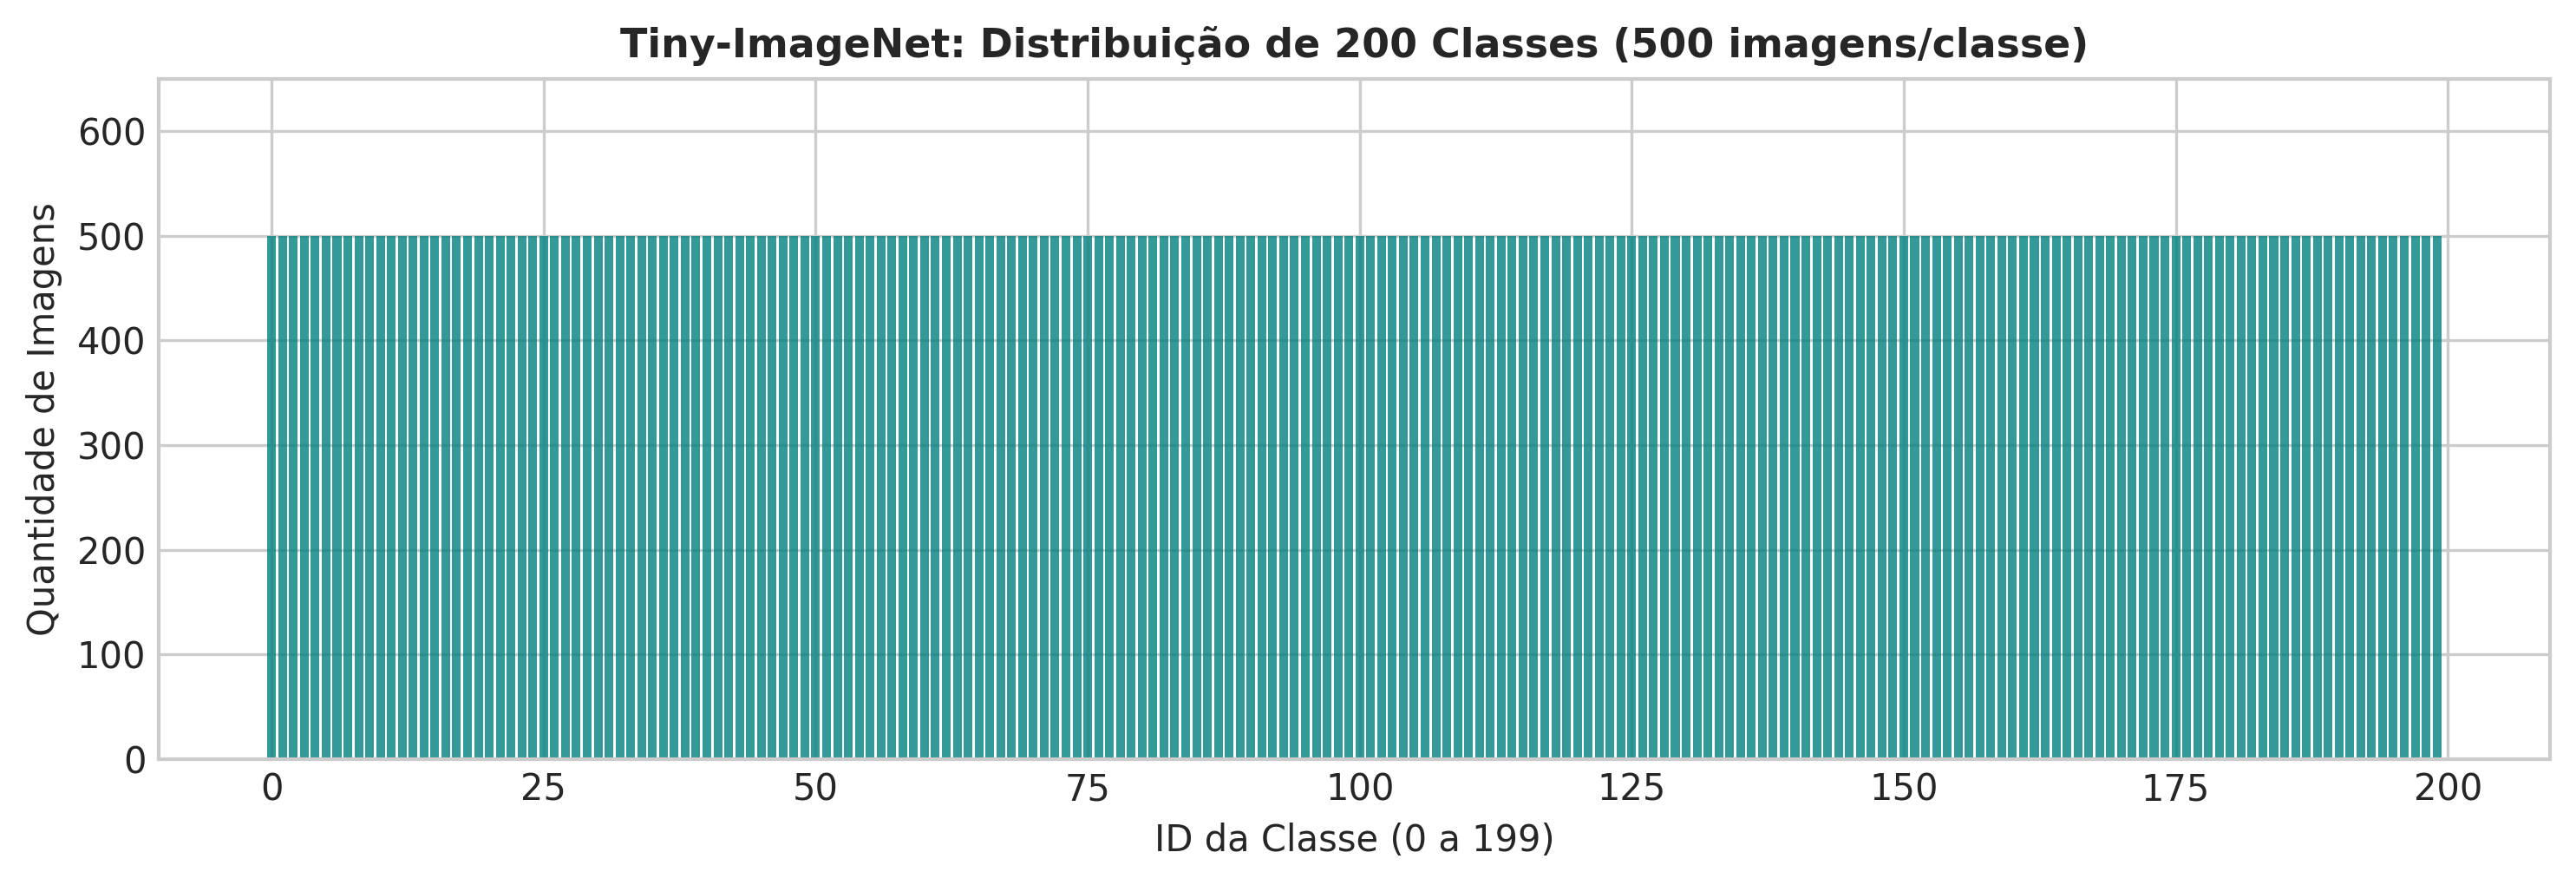

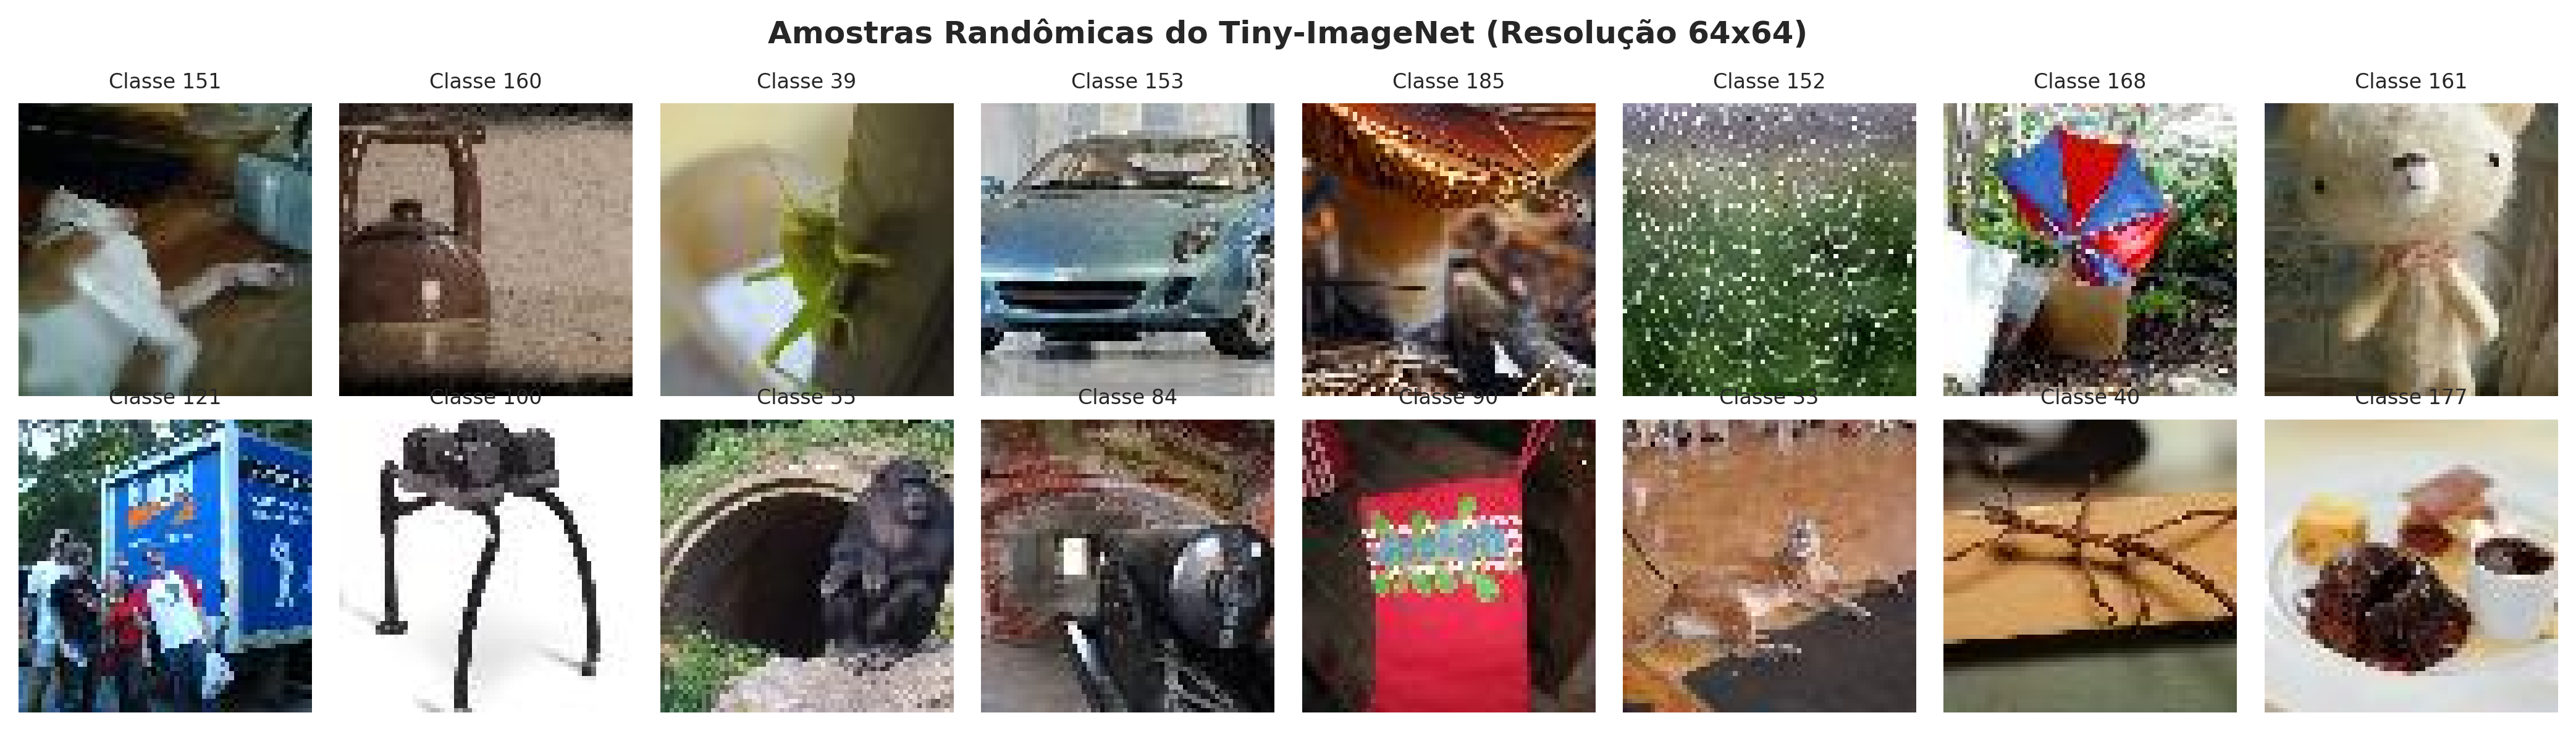

In [5]:
counts = Counter(train_dataset.targets)

# 1. Gráfico de Distribuição das 200 Classes
plt.figure(figsize=(10, 3.5))
plt.bar(list(counts.keys()), list(counts.values()), color='#008080', alpha=0.8)
plt.title('Tiny-ImageNet: Distribuição de 200 Classes (500 imagens/classe)', fontsize=11, fontweight='bold')
plt.xlabel('ID da Classe (0 a 199)')
plt.ylabel('Quantidade de Imagens')
plt.ylim(0, 650)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "eda_tiny_imagenet_distribution.png"), dpi=300, bbox_inches='tight')
plt.show()

# 2. Grade com 16 Amostras Visuais (2 linhas x 8 colunas)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
fig.suptitle("Amostras Randômicas do Tiny-ImageNet (Resolução 64x64)", fontsize=12, fontweight='bold')

np.random.seed(42)
indices = np.random.choice(len(train_dataset), 16, replace=False)

for i, idx in enumerate(indices):
    ax = axes[i // 8, i % 8]  # Indexação matricial segura (linha, coluna)
    img, label = train_dataset[idx]
    
    if img.shape[0] == 1:
        img = img.repeat(3, 1, 1)
        
    img_np = img.permute(1, 2, 0).numpy()
    
    ax.imshow(img_np)
    ax.set_title(f"Classe {label}", fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "eda_tiny_imagenet_samples.png"), dpi=300, bbox_inches='tight')
plt.show()

Estatísticas RGB e Impacto do Aumento de Tokens no ViT

In [6]:
loader = torch.utils.data.DataLoader(train_dataset, batch_size=500, shuffle=False, num_workers=2)

mean = torch.zeros(3)
std = torch.zeros(3)
total_images = 0

for images, _ in loader:
    if images.size(1) == 1:
        images = images.repeat(1, 3, 1, 1)
    batch_samples = images.size(0)
    images = images.view(batch_samples, images.size(1), -1)
    mean += images.mean(2).sum(0)
    std += images.std(2).sum(0)
    total_images += batch_samples

mean /= total_images
std /= total_images

print("=== Parâmetros para PyTorch Normalization (Tiny-ImageNet) ===")
print(f"mean = [{mean[0]:.4f}, {mean[1]:.4f}, {mean[2]:.4f}]")
print(f"std  = [{std[0]:.4f}, {std[1]:.4f}, {std[2]:.4f}]")

# Comparativo dimensional de Tokens
H_tiny, W_tiny = 64, 64
p = 4
tokens_tiny = (H_tiny // p) * (W_tiny // p)
tokens_cifar = (32 // p) * (32 // p)

print(f"\n=== Análise de Escalabilidade Computacional ===")
print(f"Tokens no CIFAR-100 (32x32, P=4): {tokens_cifar}")
print(f"Tokens no Tiny-ImageNet (64x64, P=4): {tokens_tiny}")
print(f"Aumento do comprimento da sequência: {tokens_tiny / tokens_cifar:.1f}x")
print(f"Crescimento do Custo de Atenção O(N^2): {(tokens_tiny**2) / (tokens_cifar**2):.1f}x mais computacionalmente denso!")

=== Parâmetros para PyTorch Normalization (Tiny-ImageNet) ===
mean = [0.4802, 0.4481, 0.3975]
std  = [0.2296, 0.2263, 0.2255]

=== Análise de Escalabilidade Computacional ===
Tokens no CIFAR-100 (32x32, P=4): 64
Tokens no Tiny-ImageNet (64x64, P=4): 256
Aumento do comprimento da sequência: 4.0x
Crescimento do Custo de Atenção O(N^2): 16.0x mais computacionalmente denso!
